In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder

pd.set_option('display.max_columns', None)

sns.set_style("whitegrid")

In [2]:
df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()
df.describe()
df.describe(include='object')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,3186-AJIEK,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [5]:
print(df.shape)

(7043, 21)


In [6]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
(df['TotalCharges'] == ' ').sum()

np.int64(11)

In [8]:
df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan)

In [9]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'])

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.drop_duplicates(inplace=True)

In [13]:
bins = [0,12,24,36,48,60,72]

labels = [
    '0-12',
    '13-24',
    '25-36',
    '37-48',
    '49-60',
    '61-72'
]

df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=bins,
    labels=labels
)

In [15]:
df['AvgMonthlySpend'] = (
    df['TotalCharges'] /
    df['tenure'].replace(0,1)
)
binary_cols = [
    'Partner',
    'Dependents',
    'PhoneService',
    'PaperlessBilling',
    'Churn'
]

for col in binary_cols:
    df[col] = df[col].map({
        'Yes':1,
        'No':0
    })

In [16]:
df['SeniorCitizen'] = df['SeniorCitizen'].astype(int)

In [17]:
df_encoded = pd.get_dummies(
    df,
    columns=[
        'Contract',
        'InternetService',
        'PaymentMethod'
    ],
    drop_first=True
)

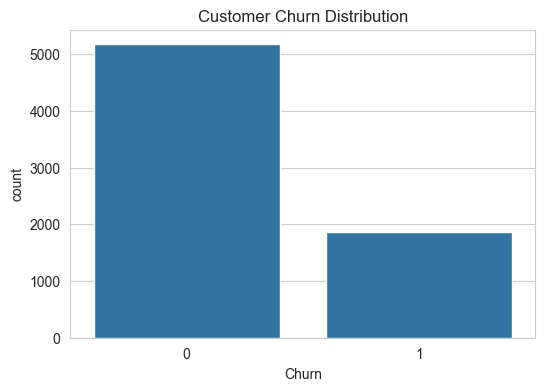

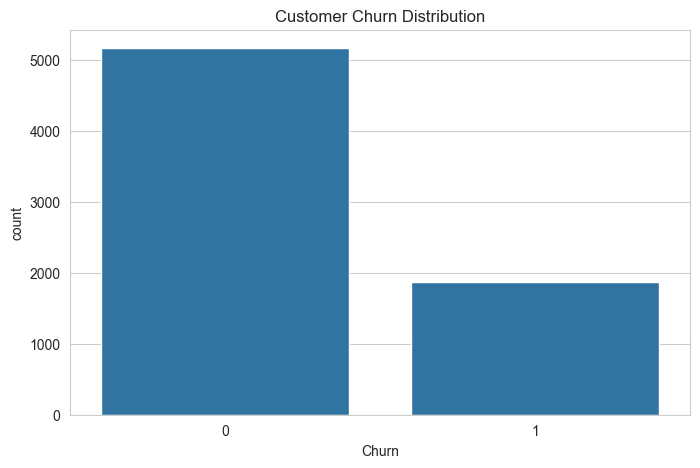

In [27]:
plt.figure(figsize=(6,4))

sns.countplot(
    x='Churn',
    data=df
)

plt.title("Customer Churn Distribution")

plt.show()
plt.figure(figsize=(8,5))

sns.countplot(x='Churn', data=df)

plt.title('Customer Churn Distribution')

plt.savefig('../visuals/churn_distribution.png',
            dpi=300,
            bbox_inches='tight')

plt.show()

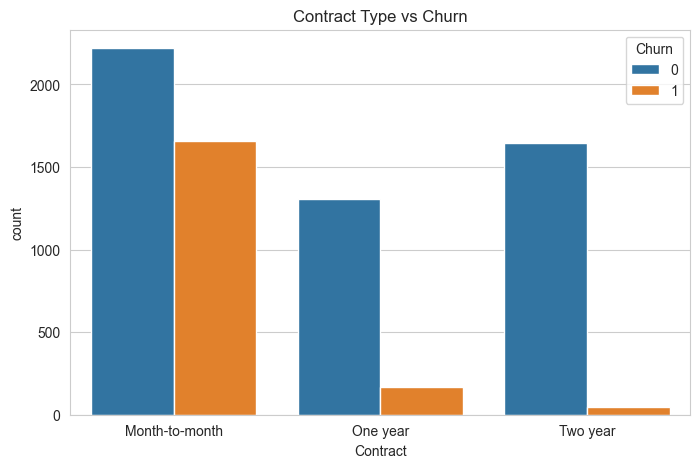

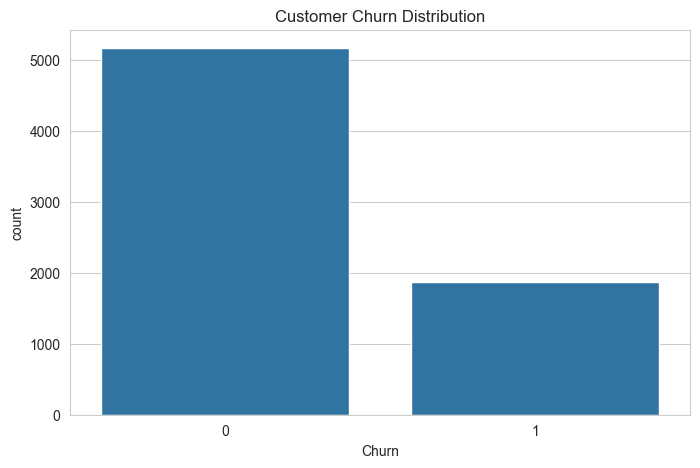

In [28]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Contract',
    hue='Churn',
    data=df
)

plt.title("Contract Type vs Churn")

plt.show()
plt.figure(figsize=(8,5))

sns.countplot(x='Churn', data=df)

plt.title('Customer Churn Distribution')

plt.savefig('../visuals/churn_distribution.png',
            dpi=300,
            bbox_inches='tight')

plt.show()

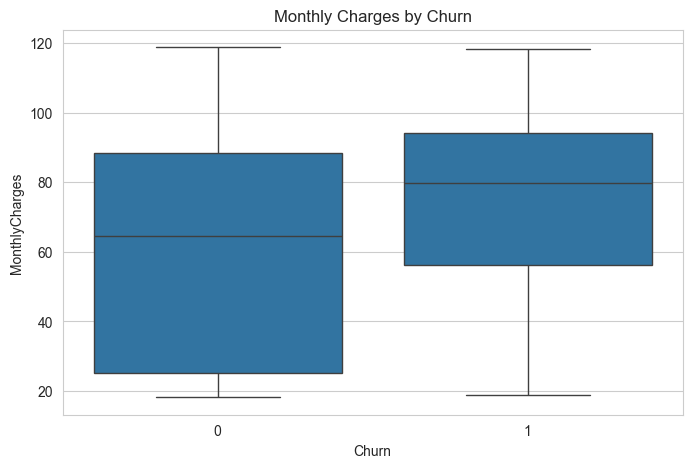

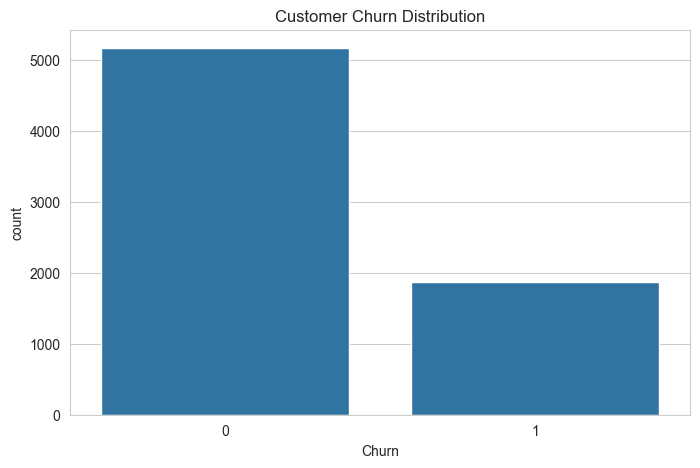

In [29]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Churn',
    y='MonthlyCharges',
    data=df
)

plt.title("Monthly Charges by Churn")

plt.show()
plt.figure(figsize=(8,5))

sns.countplot(x='Churn', data=df)

plt.title('Customer Churn Distribution')

plt.savefig('../visuals/churn_distribution.png',
            dpi=300,
            bbox_inches='tight')

plt.show()

In [30]:
df.to_csv(
    "../data/cleaned/churn_cleaned.csv",
    index=False
)

# Top 5 Business Insights

## Insight 1: Month-to-Month Customers Churn the Most
Customers on month-to-month contracts exhibit significantly higher churn rates than customers on one-year or two-year contracts.

Business Impact:
Long-term contracts improve customer retention and reduce revenue loss.

---

## Insight 2: Higher Monthly Charges Increase Churn Risk
Customers paying higher monthly charges are more likely to leave the company.

Business Impact:
Pricing strategy and customer value perception directly affect retention.

---

## Insight 3: New Customers Are More Likely to Churn
Customers with less than 12 months of tenure show the highest churn rates.

Business Impact:
The first year is the most critical period for customer engagement.

---

## Insight 4: Fiber Optic Users Show Higher Churn
Customers using fiber optic internet services demonstrate higher churn compared to DSL users.

Business Impact:
Potential service quality, pricing, or expectation gaps should be investigated.

---

## Insight 5: Electronic Check Customers Churn More Frequently
Customers paying through electronic checks have noticeably higher churn rates.

Business Impact:
Payment behavior can be used as an early warning indicator for churn.

# Business Recommendations

1. Offer discounts for customers moving from month-to-month to annual contracts.

2. Launch onboarding programs targeting customers within their first 12 months.

3. Review pricing strategies for customers with high monthly charges.

4. Investigate service quality and customer satisfaction among fiber optic users.

5. Build churn prediction alerts for customers using electronic checks and high-risk contract types.

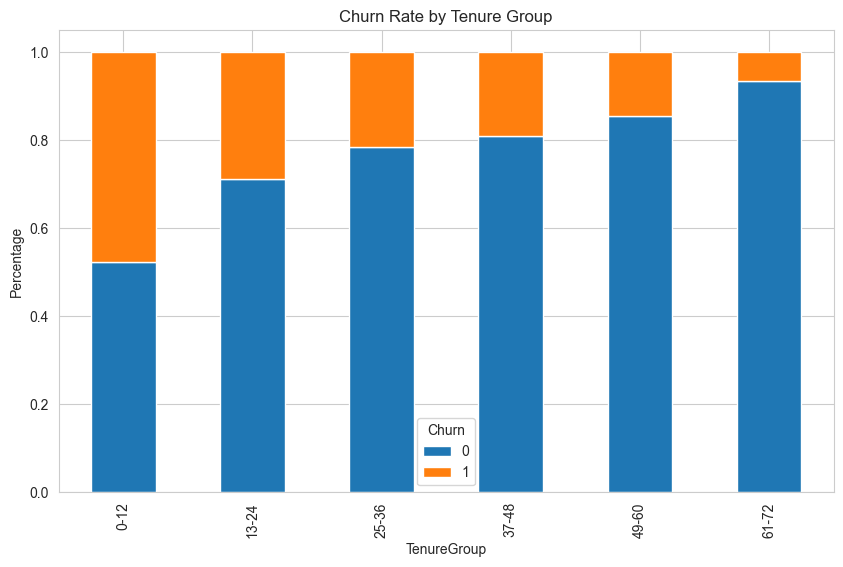

In [31]:
# Churn Rate by Tenure Group

churn_tenure = pd.crosstab(
    df['TenureGroup'],
    df['Churn'],
    normalize='index'
)

churn_tenure.plot(
    kind='bar',
    stacked=True,
    figsize=(10,6)
)

plt.title("Churn Rate by Tenure Group")
plt.ylabel("Percentage")
plt.show()

<Axes: xlabel='InternetService', ylabel='count'>

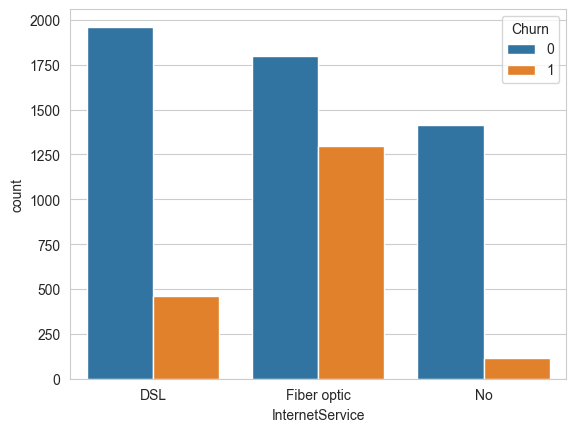

In [32]:
# Churn by Internet Service
sns.countplot(
    x='InternetService',
    hue='Churn',
    data=df
)

([0, 1, 2, 3],
 [Text(0, 0, 'Electronic check'),
  Text(1, 0, 'Mailed check'),
  Text(2, 0, 'Bank transfer (automatic)'),
  Text(3, 0, 'Credit card (automatic)')])

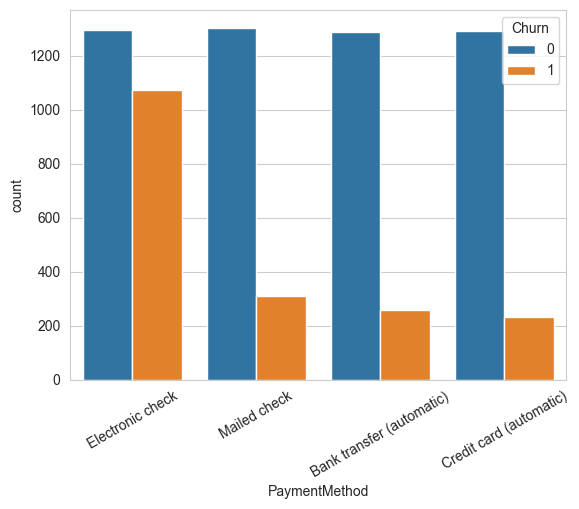

In [33]:
# Payment Method vs Churn
sns.countplot(
    x='PaymentMethod',
    hue='Churn',
    data=df
)
plt.xticks(rotation=30)

<Axes: xlabel='TenureGroup', ylabel='count'>

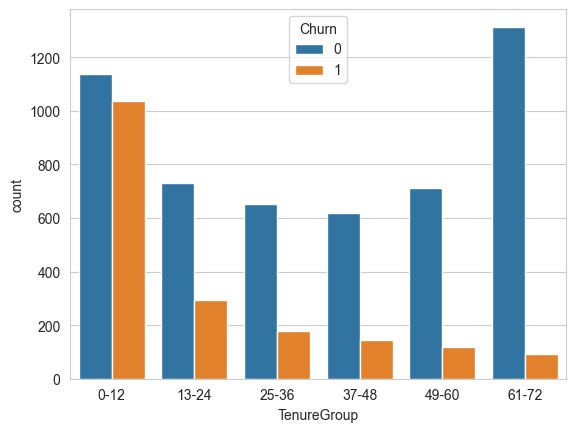

In [34]:
# Tenure Group vs Churn
sns.countplot(
    x='TenureGroup',
    hue='Churn',
    data=df
)

Business Impact Simulation

If churn is reduced by 5%, annual customer retention could improve significantly, reducing acquisition costs and increasing recurring revenue.